# Évolution des cancers — étude statistique

Ce notebook reprend l'exploration initiale et corrige les manques identifiés :

- **Intervalle de confiance à 95 %** sur chaque pente de régression, pas juste la pente seule
- **Test de significativité** (p-value) : une pente peut être non nulle juste par bruit d'échantillonnage
- **R²** conservé pour juger la qualité du fit
- **Diagnostic des résidus** sur les deux tendances agrégées qui portent la conclusion du deck (groupe "lié pesticides" vs groupe "non lié")
- La liste des cancers "liés pesticides" est reprise du notebook d'origine, mais isolée et documentée pour qu'elle soit modifiable facilement

Variable étudiée : **Taux standardisés (Europe)**, pour neutraliser l'effet de structure d'âge de la population.

Limite qui reste entière et qu'aucun indicateur statistique ne corrige : le registre ne permet pas de contrôler le dépistage, le tabagisme ou l'obésité. Une tendance significative reste une corrélation temporelle, pas une preuve de lien causal aux pesticides.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

VARIABLE = "Taux standardisés (Europe)"
ALPHA = 0.05  # seuil de significativité

df = pd.read_excel("../data/table_tous.xlsx")
df = df[df["Sexe"] == "tous"].copy()
df["Localisation"] = df["Localisation"].str.strip()
print(df.shape)
df.head()

(525, 7)


,Localisation,Effectif,Taux,Taux standardisés (Europe),Taux standardisés (Monde),Année,Sexe
0,Prostate,1958,111.3,72.7,49.7,2008,tous
1,Colon rectum,1459,83.0,47.5,31.3,2008,tous
2,Sein,1437,81.7,62.8,46.4,2008,tous
3,"Poumon, bronche et trachée",1102,62.7,45.1,31.9,2008,tous
4,Rein,386,21.9,14.7,10.3,2008,tous


## 1. Liste des cancers liés aux pesticides

Reprise du notebook d'exploration d'origine (`exploration_tous.ipynb`), basée sur le tableau de
présomption Inserm 2021 discuté dans la conversation "Pesticides et cancers : sources
scientifiques". À modifier ici si la liste doit évoluer — tout le reste du notebook en dépend.

**Correction apportée** : le notebook d'origine cherchait "Lymphome diffus à grandes cellules B",
qui ne matchait aucune ligne. Les données extraites des PDF du registre contiennent une coquille
d'OCR — "Lymphome di us à grandes cellules B" — qui faisait disparaître silencieusement ce cancer
du groupe "liés pesticides" (7 cancers comptés au lieu de 8). Corrigé ici en alignant la liste sur
le libellé réel des données ; l'idéal à terme est de corriger la coquille à la source, dans
`run_etl.py`.

In [2]:
PEST_LIST = [
    "Lymphome di us à grandes cellules B",  # coquille d'extraction OCR dans les données
                                             # source : "diffus" -> "di us" (perte du "ff")
    "Prostate",
    "Poumon, bronche et trachée",
    "Sein",
    "Myélome multiple et plasmocytome",
    "LLC / Lymphome lymphocytique",
    "Leucémie aiguë myéloïde",
    "Syndrome myélodysplasique",
]

def is_pest(loc):
    return any(p in loc for p in PEST_LIST)

df["lien_pesticide"] = df["Localisation"].apply(is_pest).astype("boolean")
df.loc[df["Localisation"].isin(["TOTAL", "Autres"]), "lien_pesticide"] = pd.NA

print(f"{df.loc[df['lien_pesticide']==True, 'Localisation'].nunique()} cancers classés 'liés pesticides'")
sorted(df.loc[df["lien_pesticide"] == True, "Localisation"].unique())

8 cancers classés 'liés pesticides'


['LLC / Lymphome lymphocytique',
 'Leucémie aiguë myéloïde',
 'Lymphome di us à grandes cellules B',
 'Myélome multiple et plasmocytome',
 'Poumon, bronche et trachée',
 'Prostate',
 'Sein',
 'Syndrome myélodysplasique']

In [3]:
# Coquille d'OCR d'extraction PDF ("diffus" -> "di us", perte du "ff") : le libellé brut est
# nécessaire pour matcher les lignes de `df`, mais ne doit jamais apparaître tel quel dans un
# titre de graphique ou un export destiné à être lu. DISPLAY_FIX corrige uniquement l'affichage.
DISPLAY_FIX = {"Lymphome di us à grandes cellules B": "Lymphome diffus à grandes cellules B"}


## 2. Fonction de régression avec indicateurs complets

Pour chaque série (année, taux), on calcule :

- la pente et son intervalle de confiance à 95 % (loi de Student, n-2 degrés de liberté)
- la p-value du test « la pente est-elle différente de 0 »
- le R²
- une étiquette de significativité

Avec seulement 15 points par cancer, ces tests ont une puissance statistique limitée — une pente
« non significative » peut aussi juste refléter un manque de données, pas forcément une absence
réelle de tendance. C'est indiqué dans le tableau plutôt que masqué.

In [4]:
def regression_stats(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    res = stats.linregress(x, y)
    slope, intercept, r, p, se = res.slope, res.intercept, res.rvalue, res.pvalue, res.stderr
    t_crit = stats.t.ppf(1 - ALPHA / 2, df=n - 2)
    ci_low = slope - t_crit * se
    ci_high = slope + t_crit * se
    if p < ALPHA and slope > 0:
        label = "hausse significative"
    elif p < ALPHA and slope < 0:
        label = "baisse significative"
    else:
        label = "non significatif"
    return {
        "n": n,
        "pente": slope,
        "IC95_bas": ci_low,
        "IC95_haut": ci_high,
        "p_value": p,
        "r2": r ** 2,
        "significativite": label,
    }

## 3. Tableau des indicateurs, tous cancers

Un cancer par ligne, TOTAL et Autres exclus de l'analyse individuelle (TOTAL est traité à part en
section 5, Autres est un fourre-tout hétérogène qui n'a pas de sens à interpréter comme une
tendance).

In [5]:
rows = []
for loc, g in df[~df["Localisation"].isin(["TOTAL", "Autres"])].groupby("Localisation"):
    g = g.sort_values("Année")
    stats_dict = regression_stats(g["Année"], g[VARIABLE])
    rows.append({"Localisation": loc, "lien_pesticide": g["lien_pesticide"].iloc[0], **stats_dict})

summary = pd.DataFrame(rows).sort_values(["lien_pesticide", "p_value"], ascending=[False, True])
summary_display = summary.copy()
for c in ["pente", "IC95_bas", "IC95_haut", "p_value", "r2"]:
    summary_display[c] = summary_display[c].round(4)
summary_display

,Localisation,lien_pesticide,n,pente,IC95_bas,IC95_haut,p_value,r2,significativite
7,Leucémie aiguë myéloïde,True,15,0.1396,0.0976,0.1817,0.0000,0.7983,hausse significative
23,"Poumon, bronche et trachée",True,15,0.4257,0.2524,0.5990,0.0001,0.6841,hausse significative
13,Lymphome di us à grandes cellules B,True,15,0.0654,0.0149,0.1158,0.0150,0.3761,hausse significative
26,Sein,True,15,0.3321,0.0577,0.6066,0.0214,0.3447,hausse significative
18,Myélome multiple et plasmocytome,True,15,0.0529,0.0015,0.1042,0.0446,0.2755,hausse significative
5,LLC / Lymphome lymphocytique,True,15,0.0393,-0.0139,0.0925,0.1347,0.1637,non significatif
27,Syndrome myélodysplasique,True,15,0.0443,-0.0272,0.1157,0.2034,0.1212,non significatif
24,Prostate,True,15,-0.3496,-1.0998,0.4005,0.3324,0.0723,non significatif
1,Colon rectum,False,15,-0.5496,-0.7671,-0.3322,0.0001,0.6965,baisse significative
22,Pancréas,False,15,0.2321,0.1397,0.3246,0.0001,0.6935,hausse significative


In [6]:
# Combien de tendances sont réellement significatives, par groupe
summary.groupby(["lien_pesticide", "significativite"]).size().unstack(fill_value=0)

significativite,baisse significative,hausse significative,non significatif
lien_pesticide,,,
False,5,3,17
True,0,5,3


**Lecture** : seules les lignes avec `significativite != "non significatif"` supportent une
vraie affirmation de tendance. Les autres pentes, même positives ou négatives à l'œil, ne sont pas
distinguables du bruit avec 15 points de données.

## 4. Graphiques individuels, avec bande de confiance

Chaque graphique reprend le point de données, la droite de régression, et sa bande de confiance à
95 %. Le titre indique la significativité — c'est la façon la plus directe de voir d'un coup d'œil
quelles tendances sont solides.

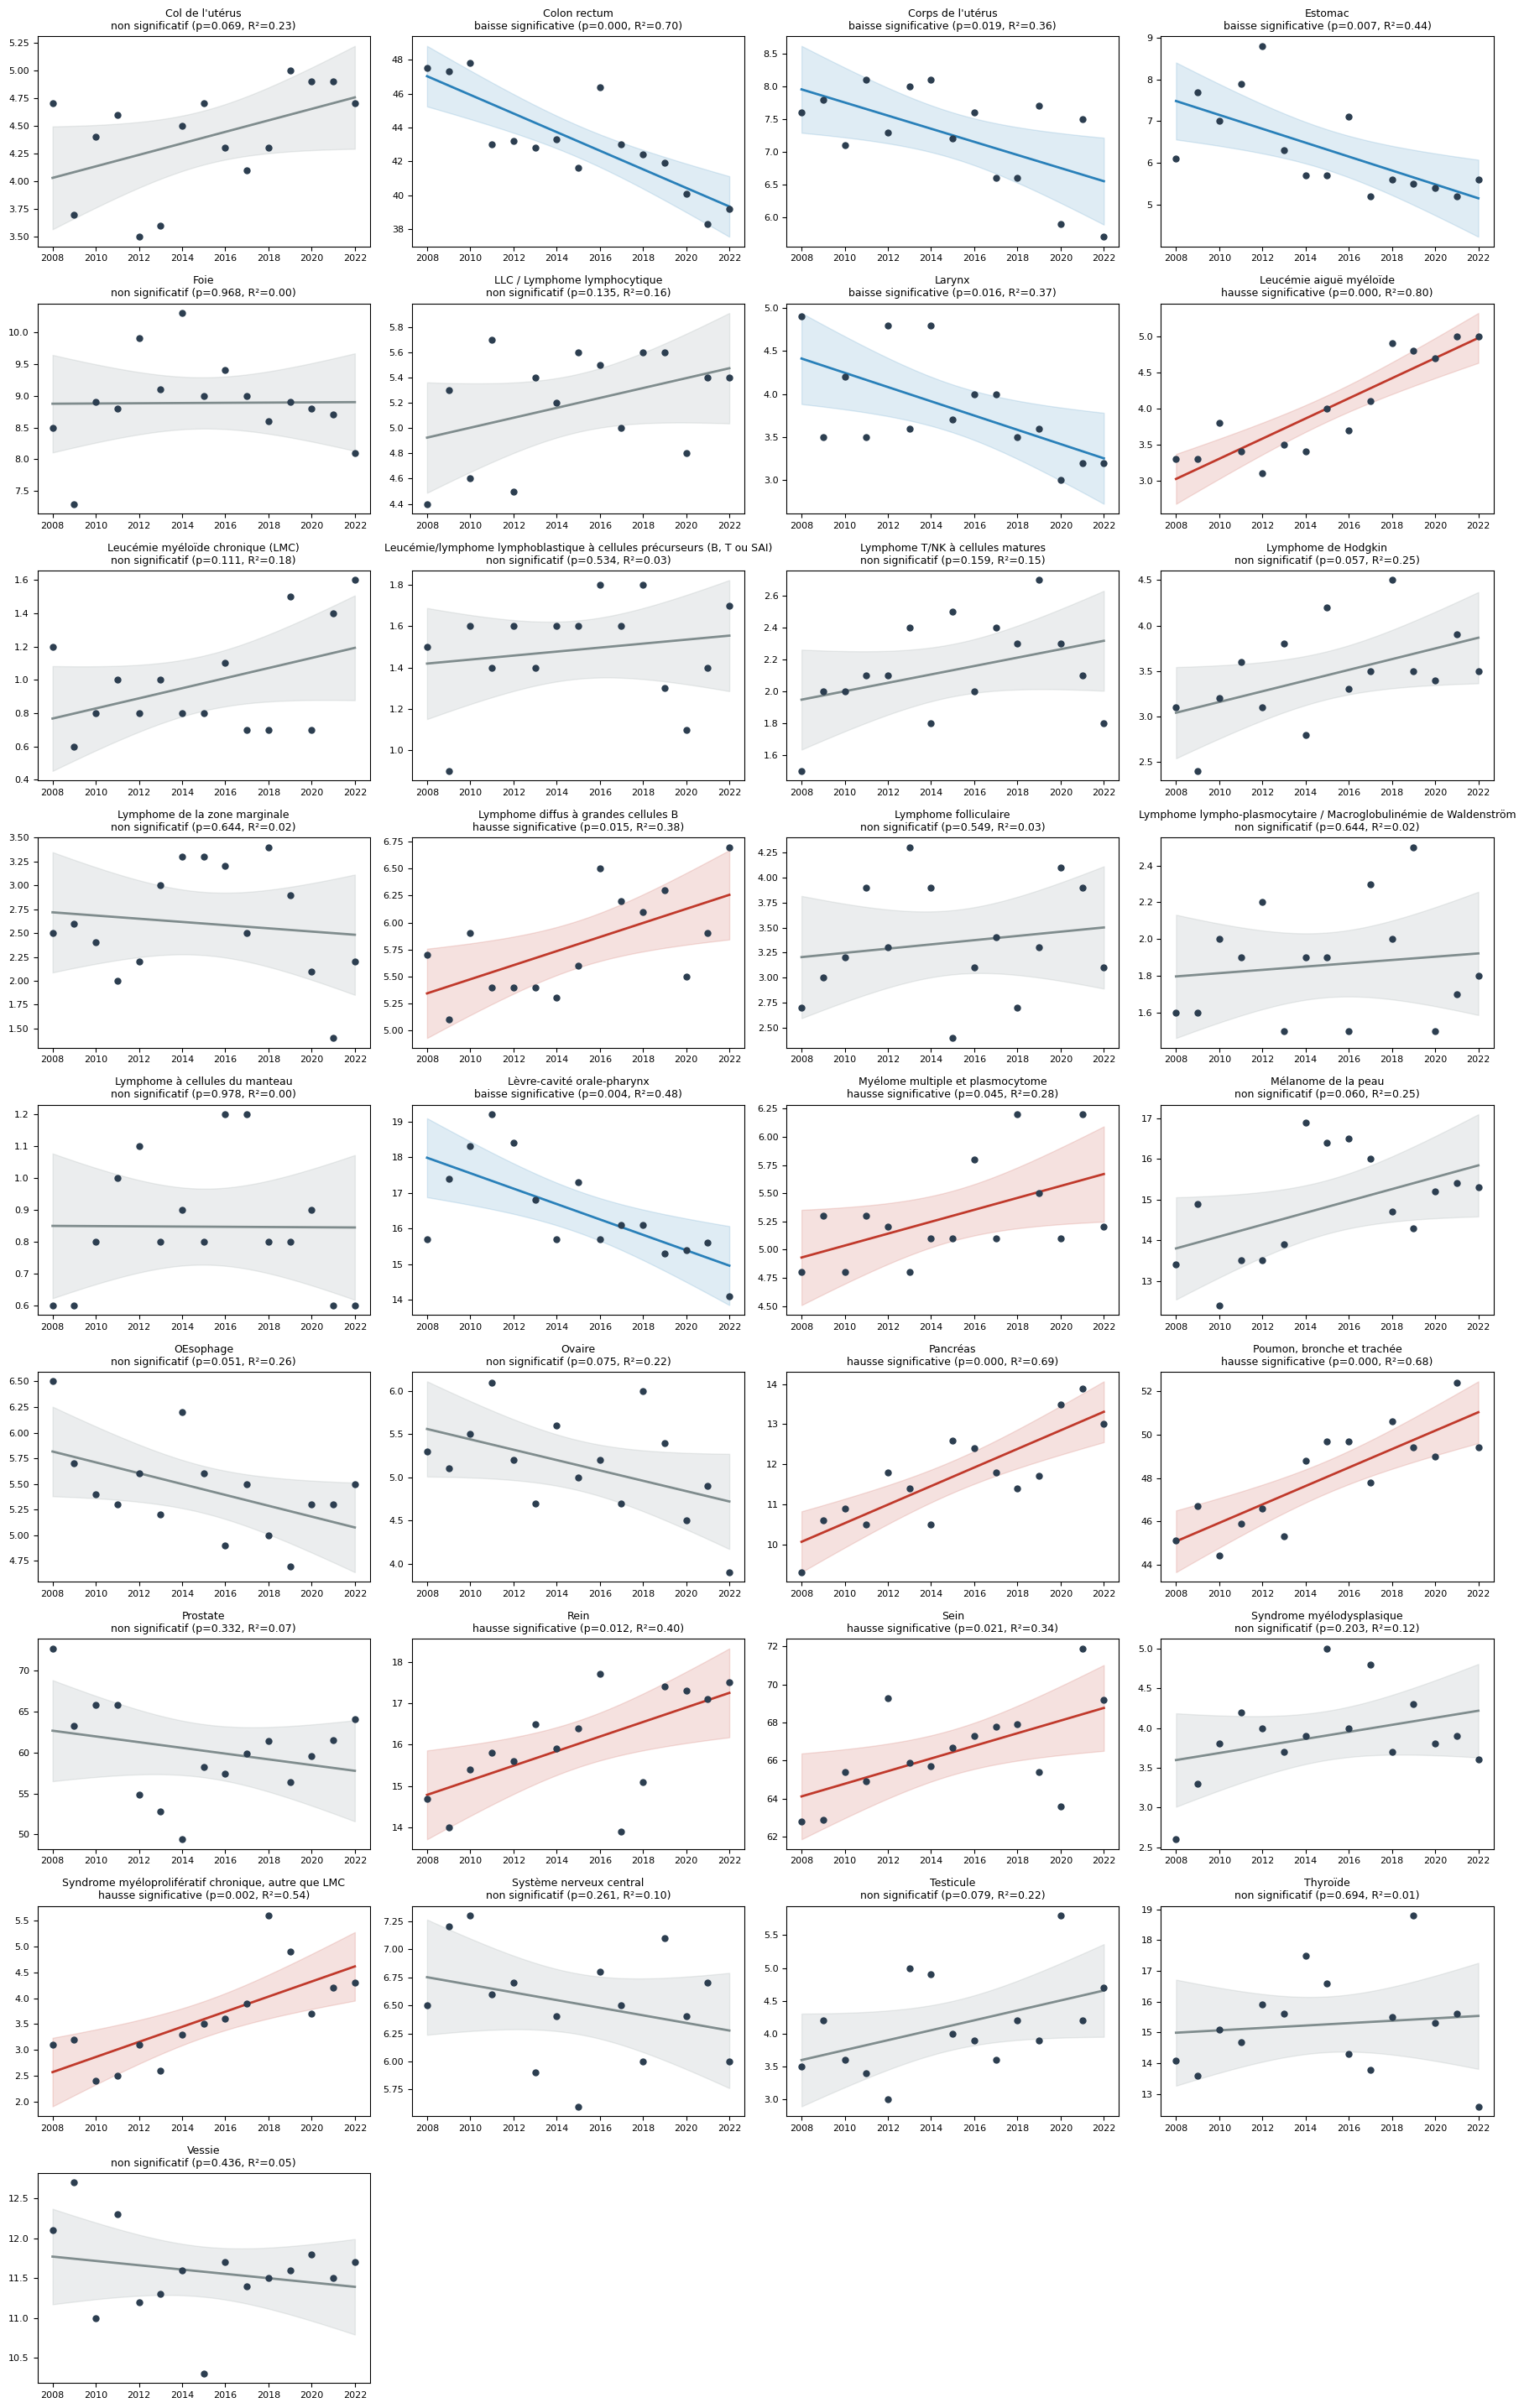

In [7]:
def plot_trend(ax, loc):
    g = df[df["Localisation"] == loc].sort_values("Année")
    x = g["Année"].values.astype(float)
    y = g[VARIABLE].values.astype(float)
    st = regression_stats(x, y)

    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y.mean() - st["pente"] * x.mean())

    # bande de confiance de la droite (pas juste de la pente) via l'erreur standard de prédiction
    n = len(x)
    x_mean = x.mean()
    s_err = np.sqrt(np.sum((y - (st["pente"] * x + (y.mean() - st["pente"] * x_mean))) ** 2) / (n - 2))
    se_fit = s_err * np.sqrt(1 / n + (x_fit - x_mean) ** 2 / np.sum((x - x_mean) ** 2))
    t_crit = stats.t.ppf(1 - ALPHA / 2, df=n - 2)

    color = {"hausse significative": "#c0392b", "baisse significative": "#2980b9",
             "non significatif": "#7f8c8d"}[st["significativite"]]

    ax.scatter(x, y, color="#2c3e50", s=25, zorder=3)
    ax.plot(x_fit, y_fit, color=color, linewidth=2)
    ax.fill_between(x_fit, y_fit - t_crit * se_fit, y_fit + t_crit * se_fit, color=color, alpha=0.15)
    label = DISPLAY_FIX.get(loc, loc)
    ax.set_title(f"{label}\n{st['significativite']} (p={st['p_value']:.3f}, R²={st['r2']:.2f})",
                 fontsize=9)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.tick_params(labelsize=8)

locs = sorted(df.loc[~df["Localisation"].isin(["TOTAL", "Autres"]), "Localisation"].unique())
n_cols = 4
n_rows = int(np.ceil(len(locs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
for ax, loc in zip(axes.flat, locs):
    plot_trend(ax, loc)
for ax in axes.flat[len(locs):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("../data/graphes_indicateurs_complets.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Comparaison agrégée : cancers liés pesticides vs non liés

C'est la comparaison qui porte la conclusion de la slide 3 du deck (« on tend vers 50-50 »). On
reprend ici la même logique que le notebook d'origine — sommer le taux standardisé sur les cancers
du groupe, par année — mais avec IC95 et p-value sur la pente de chaque groupe, plus un diagnostic
des résidus, puisque c'est le calcul qui doit être le plus solide de tout le document.

In [8]:
agg = (df[df["lien_pesticide"].notna()]
       .groupby(["Année", "lien_pesticide"])[VARIABLE]
       .sum()
       .reset_index())

pest = agg[agg["lien_pesticide"] == True].sort_values("Année")
non_pest = agg[agg["lien_pesticide"] == False].sort_values("Année")

st_pest = regression_stats(pest["Année"], pest[VARIABLE])
st_non_pest = regression_stats(non_pest["Année"], non_pest[VARIABLE])

pd.DataFrame([{"groupe": "liés pesticides", **st_pest},
              {"groupe": "non liés pesticides", **st_non_pest}]).round(4)

,groupe,n,pente,IC95_bas,IC95_haut,p_value,r2,significativite
0,liés pesticides,15,0.7496,-0.0786,1.5779,0.0724,0.2273,non significatif
1,non liés pesticides,15,-0.2821,-0.8658,0.3015,0.3154,0.0774,non significatif


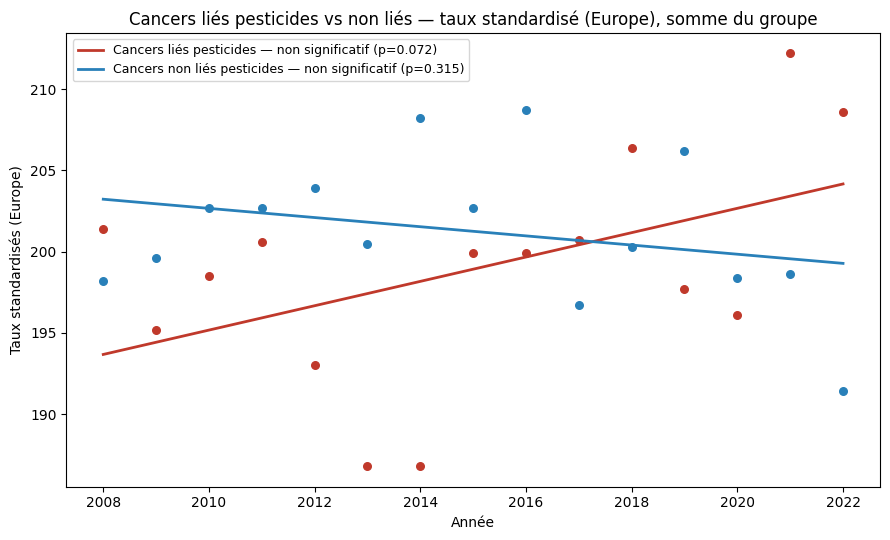

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for data, st, label, color in [
    (pest, st_pest, "Cancers liés pesticides", "#c0392b"),
    (non_pest, st_non_pest, "Cancers non liés pesticides", "#2980b9"),
]:
    x = data["Année"].values.astype(float)
    y = data[VARIABLE].values.astype(float)
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y.mean() - st["pente"] * x.mean())
    ax.scatter(x, y, color=color, s=30)
    ax.plot(x_fit, y_fit, color=color, linewidth=2,
            label=f"{label} — {st['significativite']} (p={st['p_value']:.3f})")

ax.set_xlabel("Année")
ax.set_ylabel(VARIABLE)
ax.legend(fontsize=9)
ax.set_title("Cancers liés pesticides vs non liés — taux standardisé (Europe), somme du groupe")
plt.tight_layout()
plt.savefig("../data/comparaison_groupes_indicateurs_complets.png", dpi=150, bbox_inches="tight")
plt.show()

### Diagnostic des résidus, groupe par groupe

Trois vérifications : les résidus sont-ils centrés sans motif visible, à peu près normaux (test de
Shapiro-Wilk), et non autocorrélés (test de Durbin-Watson, important ici puisque c'est une série
temporelle). Avec seulement 15 points, ces tests ont une puissance faible — à lire comme un signal
d'alerte, pas comme une validation définitive.

--- Liés pesticides ---
Shapiro-Wilk p-value (normalité) : 0.420 -> résidus proches de la normale
Durbin-Watson : 1.31 -> autocorrélation possible, prudence sur la p-value
--- Non liés pesticides ---
Shapiro-Wilk p-value (normalité) : 0.665 -> résidus proches de la normale
Durbin-Watson : 1.70 -> pas d’autocorrélation marquée


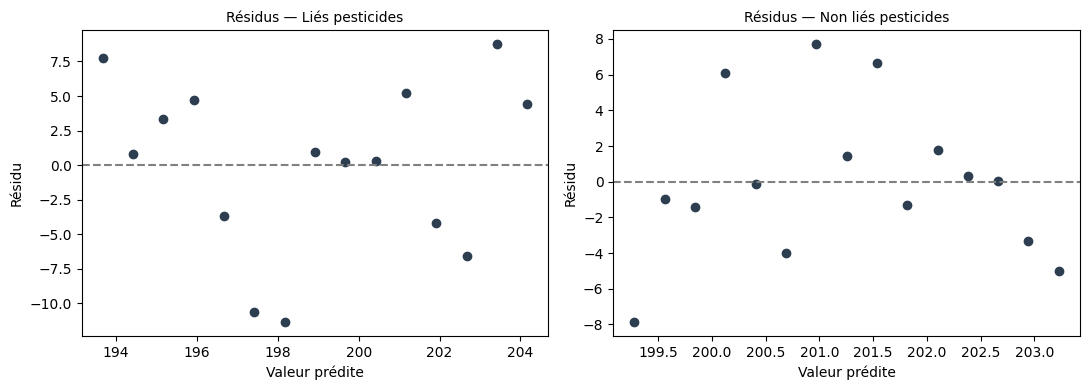

In [10]:
def residual_diagnostics(data, label):
    x = data["Année"].values.astype(float)
    y = data[VARIABLE].values.astype(float)
    slope, intercept, *_ = stats.linregress(x, y)
    y_pred = slope * x + intercept
    resid = y - y_pred

    shapiro_p = stats.shapiro(resid).pvalue
    dw = np.sum(np.diff(resid) ** 2) / np.sum(resid ** 2)  # Durbin-Watson

    print(f"--- {label} ---")
    print(f"Shapiro-Wilk p-value (normalité) : {shapiro_p:.3f}"
          f" -> {'résidus proches de la normale' if shapiro_p > ALPHA else 'écart à la normalité détecté'}")
    print(f"Durbin-Watson : {dw:.2f}"
          f" -> {'pas d’autocorrélation marquée' if 1.5 < dw < 2.5 else 'autocorrélation possible, prudence sur la p-value'}")
    return resid, y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (data, label) in zip(axes, [(pest, "Liés pesticides"), (non_pest, "Non liés pesticides")]):
    resid, y_pred = residual_diagnostics(data, label)
    ax.scatter(y_pred, resid, color="#2c3e50")
    ax.axhline(0, color="grey", linestyle="--")
    ax.set_title(f"Résidus — {label}", fontsize=10)
    ax.set_xlabel("Valeur prédite")
    ax.set_ylabel("Résidu")
plt.tight_layout()
plt.show()

## 6. Tendance globale (TOTAL)

Même traitement pour la courbe TOTAL du deck, qui donne le chiffre « +20 % en 15 ans » de la slide 1.

In [11]:
total = df[df["Localisation"] == "TOTAL"].sort_values("Année")
st_total = regression_stats(total["Année"], total[VARIABLE])
st_total_display = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in st_total.items()}
st_total_display

{'n': 15,
 'pente': np.float64(0.6),
 'IC95_bas': np.float64(-0.2584),
 'IC95_haut': np.float64(1.4584),
 'p_value': np.float64(0.155),
 'r2': np.float64(0.1492),
 'significativite': 'non significatif'}

## 7. Export

Le tableau complet des indicateurs, pour réinjection dans le PowerPoint ou dans un futur tableau de
synthèse.

In [12]:
summary.to_excel("../data/indicateurs_regression_tous_cancers.xlsx", index=False)
print("Exporté : data/indicateurs_regression_tous_cancers.xlsx")

Exporté : data/indicateurs_regression_tous_cancers.xlsx


## 8. Classification élargie par niveau de présomption (Inserm 2021)

La liste de 8 cancers utilisée plus haut ne reprenait qu'une petite partie des cancers à
présomption forte listés par l'expertise collective Inserm 2021 — notamment 2 des 7 sous-types
de lymphome non hodgkinien. Cette section reprend la classification complète, en 3 niveaux :

- **Forte** : 11 cancers, dont les 7 sous-types de LNH, la prostate, le myélome multiple, le
  système nerveux central et la leucémie/lymphome lymphoblastique (forts chez l'enfant)
- **Moyenne** : 12 cancers, dont le sein, le poumon, le rein, la vessie, le côlon-rectum...
- **Non liée** : les 10 cancers restants du registre, non documentés ou insuffisamment étudiés

Sources détaillées par cancer en section 10.

In [13]:
FORTE = [
    "Prostate", "Myélome multiple et plasmocytome", "LLC / Lymphome lymphocytique",
    "Lymphome di us à grandes cellules B", "Lymphome folliculaire",
    "Lymphome à cellules du manteau", "Lymphome de la zone marginale",
    "Lymphome T/NK à cellules matures",
    "Lymphome lympho-plasmocytaire / Macroglobulinémie de Waldenström",
    "Système nerveux central",
    "Leucémie/lymphome lymphoblastique à cellules précurseurs (B, T ou SAI)",
]
MOYENNE = [
    "Sein", "Poumon, bronche et trachée", "Leucémie aiguë myéloïde",
    "Syndrome myélodysplasique", "Rein", "Vessie", "Colon rectum",
    "Mélanome de la peau", "Testicule", "Ovaire", "Pancréas", "Thyroïde",
]
ALL_PEST = FORTE + MOYENNE
assert len(set(ALL_PEST)) == len(ALL_PEST) == 23

df["presomption"] = "Non liée"
df.loc[df["Localisation"].isin(FORTE), "presomption"] = "Forte"
df.loc[df["Localisation"].isin(MOYENNE), "presomption"] = "Moyenne"
df.loc[df["Localisation"].isin(["TOTAL", "Autres"]), "presomption"] = pd.NA

df["presomption"].value_counts(dropna=False)

presomption
Moyenne     180
Forte       165
Non liée    150
<NA>         30
Name: count, dtype: int64

### 8.1 Indicateurs pour les 23 cancers, par niveau de présomption

In [14]:
rows_pres = []
for loc, g in df[df["presomption"].notna()].groupby("Localisation"):
    g = g.sort_values("Année")
    st = regression_stats(g["Année"], g[VARIABLE])
    rows_pres.append({"Localisation": loc, "presomption": g["presomption"].iloc[0], **st})

summary_pres = pd.DataFrame(rows_pres).sort_values(["presomption", "p_value"])
summary_pres.groupby(["presomption", "significativite"]).size().unstack(fill_value=0)

significativite,baisse significative,hausse significative,non significatif
presomption,,,
Forte,0,2,9
Moyenne,1,5,6
Non liée,4,1,5


### 8.2 Comparaison indice base 100 : liés (23) vs non liés (10)

Sommer un taux standardisé sur des groupes de taille très différente (23 cancers vs 10) écrase
le graphique : le groupe le plus nombreux domine visuellement même sans écart réel. On indexe
donc chaque groupe à 100 en 2008 pour comparer des **croissances**, pas des niveaux.

Liés pesticides (23 cancers): hausse significative, p=0.027, IC95 pente=[0.03, 0.44]
Non liés (10 cancers): baisse significative, p=0.019, IC95 pente=[-0.97, -0.10]


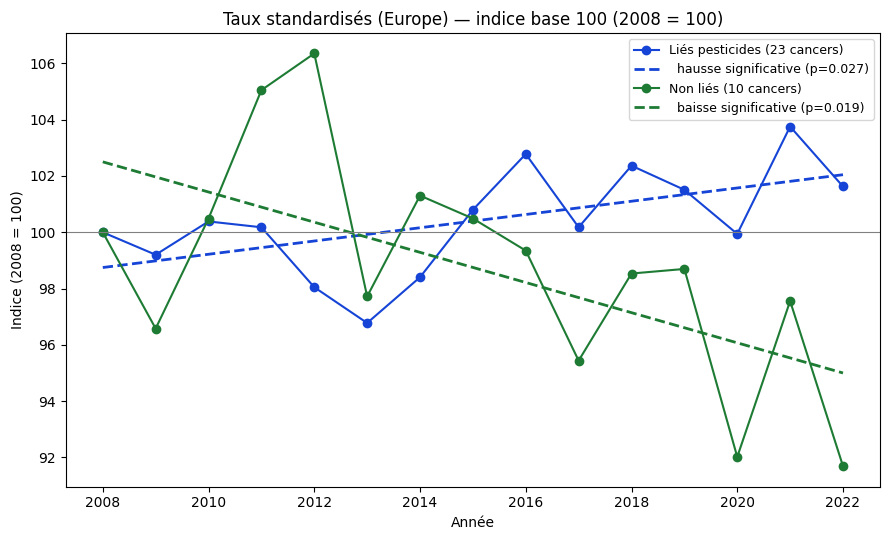

In [15]:
agg = (df[df["presomption"].notna()]
       .assign(lien=lambda d: d["presomption"] != "Non liée")
       .groupby(["Année", "lien"])[VARIABLE].mean().reset_index())
pest = agg[agg["lien"] == True].sort_values("Année")
non_pest = agg[agg["lien"] == False].sort_values("Année")

fig, ax = plt.subplots(figsize=(9, 5.5))
for data, label, color in [(pest, "Liés pesticides (23 cancers)", "#1544D6"),
                            (non_pest, "Non liés (10 cancers)", "#1E7B34")]:
    x = data["Année"].values.astype(float)
    y = data[VARIABLE].values.astype(float)
    y_idx = y / y[0] * 100
    st = regression_stats(x, y_idx)
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y_idx.mean() - st["pente"] * x.mean())
    ax.plot(x, y_idx, "o-", color=color, label=f"{label}")
    ax.plot(x_fit, y_fit, color=color, linewidth=2, linestyle="--",
            label=f"  {st['significativite']} (p={st['p_value']:.3f})")
    print(f"{label}: {st['significativite']}, p={st['p_value']:.3f}, "
          f"IC95 pente=[{st['IC95_bas']:.2f}, {st['IC95_haut']:.2f}]")

ax.axhline(100, color="grey", linewidth=0.8)
ax.set_xlabel("Année")
ax.set_ylabel("Indice (2008 = 100)")
ax.set_title(f"{VARIABLE} — indice base 100 ({int(pest['Année'].min())} = 100)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../data/comparaison_indice_base100.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultat** : avec le périmètre complet (23 cancers), l'écart entre les deux groupes
devient statistiquement significatif — hausse pour les cancers liés, baisse pour les non liés.
Avec la sélection initiale à 8 cancers (section 5), le même écart n'était pas significatif.
La classification complète change donc la conclusion, pas seulement les chiffres.

### 8.3 Même comparaison, sans standardisation par âge (taux brut)

Le taux « standardisé (Europe) » neutralise l'effet du vieillissement de la population : il
recalcule l'incidence que l'on observerait si la pyramide des âges de Poitou-Charentes était
identique à celle de la population européenne de référence. Pour vérifier que la divergence entre
les deux groupes ne vient pas uniquement de cet ajustement, on refait le même calcul avec le taux
brut (`Taux`), non corrigé de l'âge.

Liés pesticides (23 cancers): hausse significative, p=0.000, IC95 pente=[1.23, 1.76]
Non liés (10 cancers): non significatif, p=0.071, IC95 pente=[-0.04, 0.83]


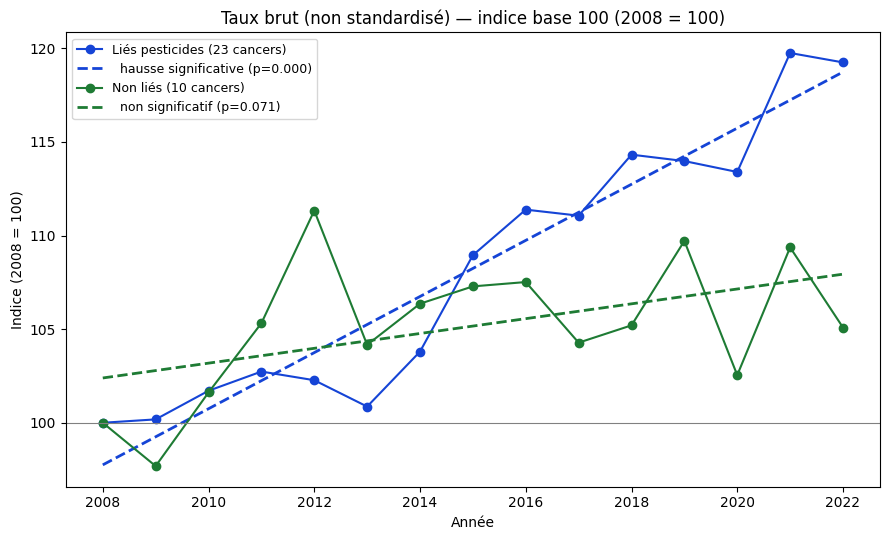

In [16]:
agg_brut = (df[df["presomption"].notna()]
       .assign(lien=lambda d: d["presomption"] != "Non liée")
       .groupby(["Année", "lien"])["Taux"].mean().reset_index())
pest_brut = agg_brut[agg_brut["lien"] == True].sort_values("Année")
non_pest_brut = agg_brut[agg_brut["lien"] == False].sort_values("Année")

fig, ax = plt.subplots(figsize=(9, 5.5))
stats_brut = {}
for data, label, color, key in [(pest_brut, "Liés pesticides (23 cancers)", "#1544D6", "lies_pesticides"),
                                 (non_pest_brut, "Non liés (10 cancers)", "#1E7B34", "non_lies_pesticides")]:
    x = data["Année"].values.astype(float)
    y = data["Taux"].values.astype(float)
    y_idx = y / y[0] * 100
    st = regression_stats(x, y_idx)
    stats_brut[key] = st
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y_idx.mean() - st["pente"] * x.mean())
    ax.plot(x, y_idx, "o-", color=color, label=f"{label}")
    ax.plot(x_fit, y_fit, color=color, linewidth=2, linestyle="--",
            label=f"  {st['significativite']} (p={st['p_value']:.3f})")
    print(f"{label}: {st['significativite']}, p={st['p_value']:.3f}, "
          f"IC95 pente=[{st['IC95_bas']:.2f}, {st['IC95_haut']:.2f}]")

ax.axhline(100, color="grey", linewidth=0.8)
ax.set_xlabel("Année")
ax.set_ylabel("Indice (2008 = 100)")
ax.set_title(f"Taux brut (non standardisé) — indice base 100 ({int(pest_brut['Année'].min())} = 100)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../data/comparaison_indice_base100_taux_brut.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Grilles par niveau de présomption

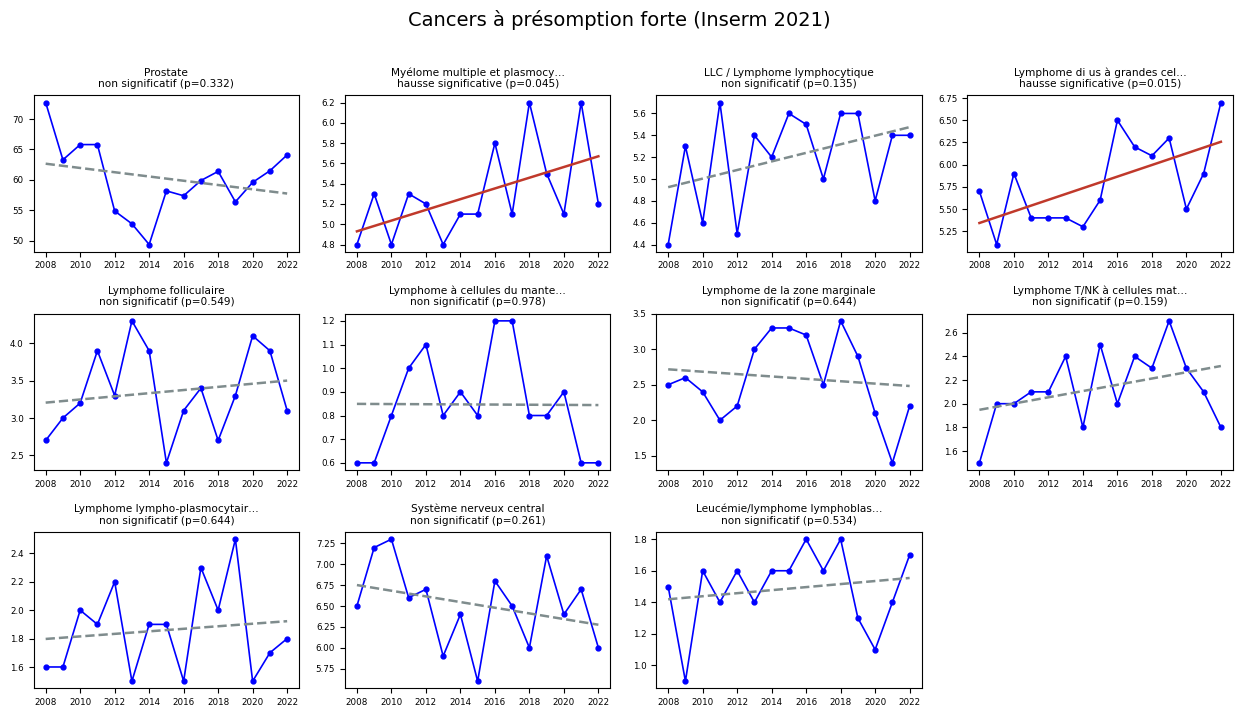

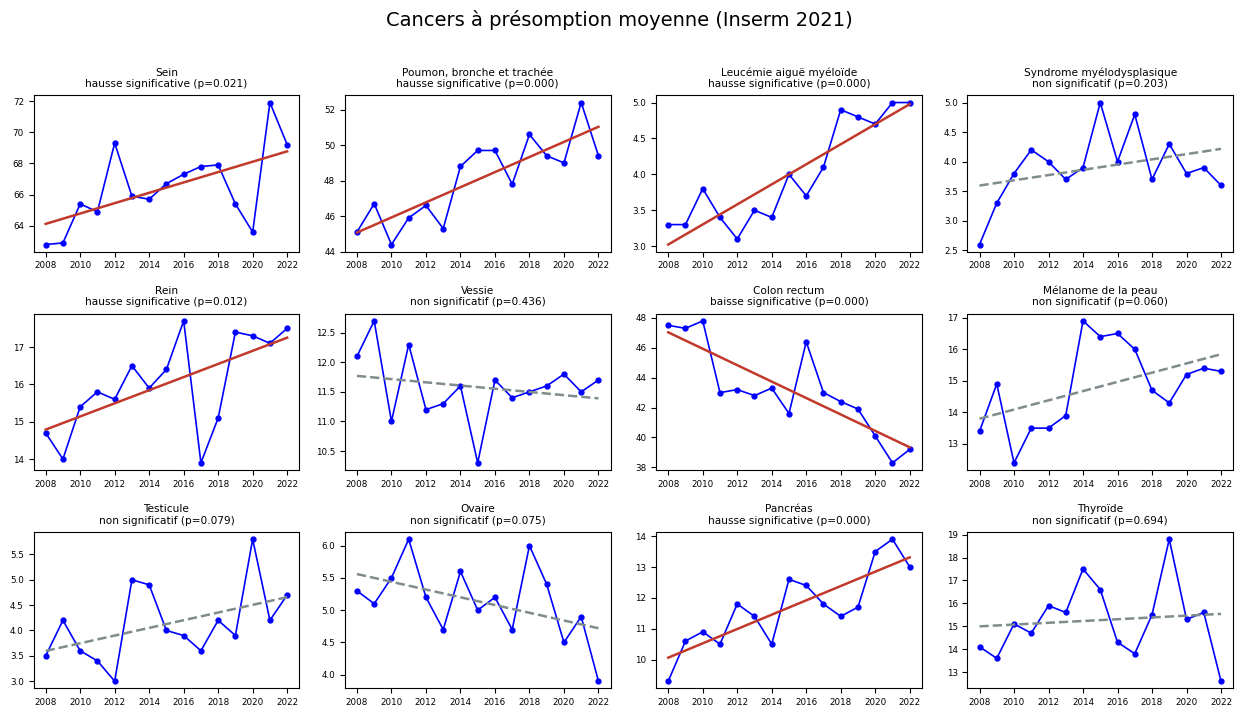

In [17]:
def make_grid(cancer_list, title, ncols=4):
    nrows = int(np.ceil(len(cancer_list) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.15, nrows * 2.35))
    axes = np.atleast_2d(axes)
    for i, cancer in enumerate(cancer_list):
        r, c = divmod(i, ncols)
        ax = axes[r, c]
        g = df[df["Localisation"] == cancer].sort_values("Année")
        x, y = g["Année"].values.astype(float), g[VARIABLE].values.astype(float)
        st = regression_stats(x, y)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = st["pente"] * x_fit + (y.mean() - st["pente"] * x.mean())
        color = "#C0392B" if st["significativite"] != "non significatif" else "#7F8C8D"
        ls = "-" if st["significativite"] != "non significatif" else "--"
        ax.plot(x, y, "o-", color="blue", markersize=3.5, linewidth=1.2)
        ax.plot(x_fit, y_fit, color=color, linewidth=1.8, linestyle=ls)
        label = cancer if len(cancer) < 30 else cancer[:28] + "…"
        ax.set_title(f"{label}\n{st['significativite']} (p={st['p_value']:.3f})", fontsize=7.6)
        ax.tick_params(labelsize=6.3)
    for i in range(len(cancer_list), nrows * ncols):
        r, c = divmod(i, ncols)
        axes[r, c].axis("off")
    fig.suptitle(title, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

make_grid(FORTE, "Cancers à présomption forte (Inserm 2021)")
make_grid(MOYENNE, "Cancers à présomption moyenne (Inserm 2021)")

## 10. Tableau complet, sources par cancer

Sources détaillées, classées par niveau de présomption. Réutilisé pour la diapo "Tableau complet
et sources" du PowerPoint.

In [18]:
SOURCE_NOTE = {
    "Prostate": "Inserm 2021, présomption forte",
    "Myélome multiple et plasmocytome": "Inserm 2021, présomption forte",
    "LLC / Lymphome lymphocytique": "Inserm 2021, LNH forte",
    "Lymphome di us à grandes cellules B": "Inserm 2021, LNH forte",
    "Lymphome folliculaire": "Inserm 2021, LNH forte",
    "Lymphome à cellules du manteau": "Inserm 2021, LNH forte",
    "Lymphome de la zone marginale": "Inserm 2021, LNH forte",
    "Lymphome T/NK à cellules matures": "Inserm 2021, LNH forte",
    "Lymphome lympho-plasmocytaire / Macroglobulinémie de Waldenström": "Inserm 2021, LNH forte",
    "Système nerveux central": "Inserm 2021, fort chez l'enfant",
    "Leucémie/lymphome lymphoblastique à cellules précurseurs (B, T ou SAI)": "Inserm 2021, fort chez l'enfant",
    "Sein": "Inserm/INRAE/Cnam, cocktails alimentaires",
    "Poumon, bronche et trachée": "Agricultural Health Study ; ARC",
    "Leucémie aiguë myéloïde": "Inserm 2021 ; thèse 2021 (OR=1,51 adulte)",
    "Syndrome myélodysplasique": "ScienceDirect 2023, preuves limitées",
    "Rein": "Inserm 2021, présomption moyenne",
    "Vessie": "Inserm 2021, présomption moyenne",
    "Colon rectum": "Inserm 2021 (AGRICAN) ; piclorame 2026",
    "Mélanome de la peau": "Ligue contre le cancer ; JCO 2025",
    "Testicule": "Ligue contre le cancer (Inserm 2021)",
    "Ovaire": "Fondation ARC ; Cancer-Environnement",
    "Pancréas": "Études PESTIPAC/EcoPESTIPAC",
    "Thyroïde": "Inserm 2021, présomption moyenne",
}
NON_LIEE_NOTE = {
    "Col de l'utérus": "Non documenté", "Corps de l'utérus": "Non documenté",
    "OEsophage": "Données insuffisantes (Inserm)", "Estomac": "Données insuffisantes (Inserm)",
    "Foie": "Données insuffisantes (Inserm)", "Larynx": "Non documenté",
    "Lèvre-cavité orale-pharynx": "Données insuffisantes (ORL)",
    "Leucémie myéloïde chronique (LMC)": "Non documenté",
    "Syndrome myéloprolifératif chronique, autre que LMC": "Non documenté",
    "Lymphome de Hodgkin": "Non documenté (vs LNH)",
}

rows_full = []
for cancer in sorted(FORTE + MOYENNE + list(NON_LIEE_NOTE.keys())):
    g = df[df["Localisation"] == cancer].sort_values("Année")
    st = regression_stats(g["Année"], g[VARIABLE])
    pres = "Forte" if cancer in FORTE else "Moyenne" if cancer in MOYENNE else "Non liée"
    source = SOURCE_NOTE.get(cancer) or NON_LIEE_NOTE.get(cancer)
    rows_full.append([cancer, pres, st["significativite"], round(st["p_value"], 4), source])

table_complete = pd.DataFrame(rows_full, columns=["Cancer", "Présomption", "Tendance", "p_value", "Source"])
table_complete = table_complete.sort_values(["Présomption", "Cancer"],
    key=lambda s: s.map({"Forte": 0, "Moyenne": 1, "Non liée": 2}) if s.name == "Présomption" else s)
table_complete.to_excel("../data/tableau_complet_sources.xlsx", index=False)
table_complete

,Cancer,Présomption,Tendance,p_value,Source
5,LLC / Lymphome lymphocytique,Forte,non significatif,0.1347,"Inserm 2021, LNH forte"
9,Leucémie/lymphome lymphoblastique à cellules p...,Forte,non significatif,0.5345,"Inserm 2021, fort chez l'enfant"
10,Lymphome T/NK à cellules matures,Forte,non significatif,0.1588,"Inserm 2021, LNH forte"
12,Lymphome de la zone marginale,Forte,non significatif,0.6439,"Inserm 2021, LNH forte"
13,Lymphome di us à grandes cellules B,Forte,hausse significative,0.0150,"Inserm 2021, LNH forte"
14,Lymphome folliculaire,Forte,non significatif,0.5492,"Inserm 2021, LNH forte"
15,Lymphome lympho-plasmocytaire / Macroglobuliné...,Forte,non significatif,0.6436,"Inserm 2021, LNH forte"
16,Lymphome à cellules du manteau,Forte,non significatif,0.9782,"Inserm 2021, LNH forte"
18,Myélome multiple et plasmocytome,Forte,hausse significative,0.0446,"Inserm 2021, présomption forte"
24,Prostate,Forte,non significatif,0.3324,"Inserm 2021, présomption forte"


## 11. Export pour le site public

Résumé structuré de tous les indicateurs calculés ci-dessus (tendance globale, comparaison à 8
cancers, comparaison élargie à 23 cancers, détail par cancer), exporté en JSON pour être consommé
tel quel par `scripts/build_site.py` sans dupliquer la logique statistique côté site.

In [19]:
import json
from datetime import datetime

site_stats = {
    "generated_at": datetime.now().strftime("%Y-%m-%d"),
    "variable_etudiee": VARIABLE,
    "alpha": ALPHA,
    "annees": {"min": int(df["Année"].min()), "max": int(df["Année"].max())},
    "total": st_total,
    "groupes_23_cancers": {},
    "groupes_23_cancers_taux_brut": stats_brut,
    "cancers": [],
}

# Comparaison indexée base 100 (section 8.2), recalculée ici pour l'export numérique
agg100 = (df[df["presomption"].notna()]
          .assign(lien=lambda d: d["presomption"] != "Non liée")
          .groupby(["Année", "lien"])[VARIABLE].mean().reset_index())
for lien_val, key in [(True, "lies_pesticides"), (False, "non_lies_pesticides")]:
    g = agg100[agg100["lien"] == lien_val].sort_values("Année")
    y_idx = g[VARIABLE].values.astype(float)
    y_idx = y_idx / y_idx[0] * 100
    site_stats["groupes_23_cancers"][key] = regression_stats(g["Année"], y_idx)

for _, row in table_complete.iterrows():
    cancer = row["Cancer"]
    g = df[df["Localisation"] == cancer].sort_values("Année")
    st = regression_stats(g["Année"], g[VARIABLE])
    site_stats["cancers"].append({
        "nom": DISPLAY_FIX.get(cancer, cancer),
        "presomption": row["Présomption"],
        "source_courte": row["Source"],
        **st,
    })

def clean(obj):
    if isinstance(obj, dict):
        return {k: clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [clean(v) for v in obj]
    if isinstance(obj, (np.floating,)):
        return round(float(obj), 4)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    return obj

with open("../data/site_stats.json", "w", encoding="utf-8") as f:
    json.dump(clean(site_stats), f, ensure_ascii=False, indent=2)

print("Exporté : data/site_stats.json")


Exporté : data/site_stats.json
